<a href="https://colab.research.google.com/github/attilaf3/MSc_Onlab_attilafarago/blob/main/UrbanReID_BABGulyas_01_data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from pathlib import Path
from urllib.request import urlretrieve
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

SEED = 2026
DATA_DIR = Path("data")
OUT = Path("outputs")

INPUT_DIR = None  # Example: Path("/content/URVAM-ReID2026")
ZIP_PATH = None   # Example: Path("/content/URVAM-ReID2026.zip")

ZENODO_URL = "https://zenodo.org/records/18875005/files/URVAM-ReID2026.zip"

DATA_DIR.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

if INPUT_DIR is not None:
    ROOT = Path(INPUT_DIR)
else:
    # Download the archive if no local ZIP was provided.
    archive_path = Path(ZIP_PATH) if ZIP_PATH else DATA_DIR / "URVAM-ReID2026.zip"

    if ZIP_PATH is None and not archive_path.is_file():
        temp_path = archive_path.with_suffix(".part")
        urlretrieve(ZENODO_URL, temp_path)
        temp_path.replace(archive_path)

    # Extract each archive into its own folder.
    extracted = DATA_DIR / archive_path.stem
    marker = extracted / ".extracted"
    archive_info = archive_path.stat()
    signature = f"{archive_path.resolve()}:{archive_info.st_size}:{archive_info.st_mtime_ns}"

    if not marker.is_file() or marker.read_text() != signature:
        with zipfile.ZipFile(archive_path) as archive:
            archive.extractall(extracted)
        marker.write_text(signature)

    # Find the main dataset and skip the external data.
    roots = [
        path.parent
        for path in extracted.rglob("train.csv")
        if all(
            (path.parent / f"image_{role}").is_dir()
            for role in ("train", "query", "test")
        )
        and not any(
            "external" in part.lower()
            for part in path.relative_to(extracted).parts
        )
    ]

    if len(roots) != 1:
        raise ValueError(f"Set INPUT_DIR to the dataset folder. Candidates: {roots}")

    ROOT = roots[0]

print("Dataset folder:", ROOT.resolve())

Dataset folder: /content/data/URVAM-ReID2026/URVAM-ReID2026


In [6]:
def find_column(frame, *names):
    # Ignore capitalization, spaces and underscores in column names.
    def normalize(name):
        return "".join(char for char in name.lower() if char.isalnum())

    columns = {normalize(name): name for name in frame.columns}
    for name in names:
        if normalize(name) in columns:
            return columns[normalize(name)]

    raise ValueError(f"Expected one of {names}. Found: {frame.columns.tolist()}")


def read_split(role):
    rows = pd.read_csv(ROOT / f"{role}.csv", dtype=str)
    classes = pd.read_csv(ROOT / f"{role}_classes.csv", dtype=str)

    name_col = find_column(rows, "imageName")
    camera_col = find_column(rows, "cameraID")
    columns = {name_col: "image_name", camera_col: "camera"}

    # Use object IDs only from the labeled training split.
    if role == "train":
        id_col = find_column(rows, "objectID", "Corresponding Indexes")
        columns[id_col] = "object_id"

    rows = rows[list(columns)].rename(columns=columns)

    class_name_col = find_column(classes, "imageName")
    class_col = find_column(
        classes, "class", "category", "objectClass", "objectType",
        "className", "objectCategory", "classID", "type", "label"
    )
    classes = classes[[class_name_col, class_col]].rename(
        columns={class_name_col: "image_name", class_col: "category"}
    )

    rows = rows.merge(
        classes, on="image_name", how="left", sort=False, validate="one_to_one"
    )
    if rows.isna().any().any():
        raise ValueError(f"Missing metadata in the {role} split.")

    rows["source_split"] = role
    rows["image_path"] = "image_" + role + "/" + rows["image_name"]
    return rows


def inspect_image(relative_path):
    path = ROOT / relative_path
    if not path.is_file():
        return None, None, "missing"

    try:
        with Image.open(path) as image:
            image.load()
            return image.width, image.height, "ok"
    except (OSError, ValueError):
        return None, None, "unreadable"


official = {role: read_split(role) for role in ("train", "query", "test")}

for rows in official.values():
    # Decode each file and record its original dimensions.
    rows[["width", "height", "status"]] = pd.DataFrame(
        [inspect_image(path) for path in rows["image_path"]],
        index=rows.index,
    )

all_images = pd.concat(official.values(), ignore_index=True)
issues = all_images.loc[all_images["status"].ne("ok")]
issues.to_csv(OUT / "image_issues.csv", index=False)

display(pd.crosstab(all_images["source_split"], all_images["status"]))

# Keep every readable training image, including small and blurry ones.
labeled = official["train"].loc[official["train"]["status"].eq("ok")].copy()
if labeled.empty:
    raise ValueError("No readable training images found.")

display(labeled.head())

status,ok
source_split,
query,928
test,2844
train,11175


,image_name,camera,object_id,category,source_split,image_path,width,height,status
0,000001.jpg,c001,0680,RubbishBins,train,image_train/000001.jpg,42,83,ok
1,000002.jpg,c001,0164,Container,train,image_train/000002.jpg,86,85,ok
2,000003.jpg,c001,0218,trafficsignal,train,image_train/000003.jpg,75,121,ok
3,000004.jpg,c001,0160,Container,train,image_train/000004.jpg,33,37,ok
4,000005.jpg,c001,0684,trafficsignal,train,image_train/000005.jpg,23,31,ok


,images,objects
category,,
Container,1189,87
Crosswalk,1532,111
RubbishBins,886,115
trafficsignal,7568,800


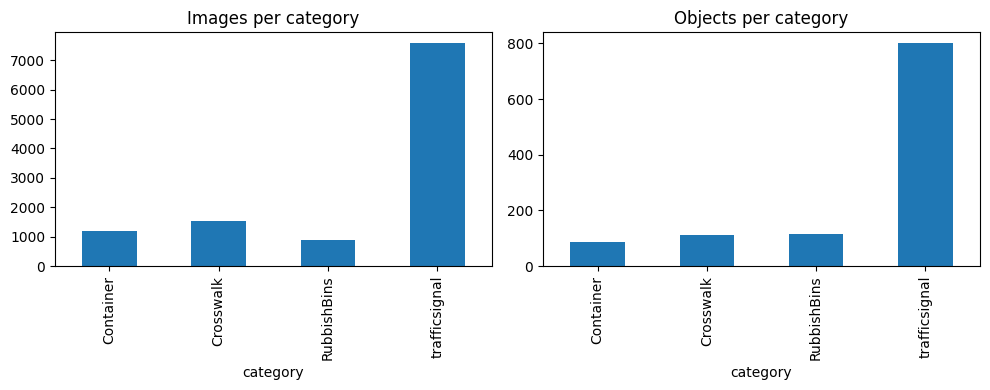

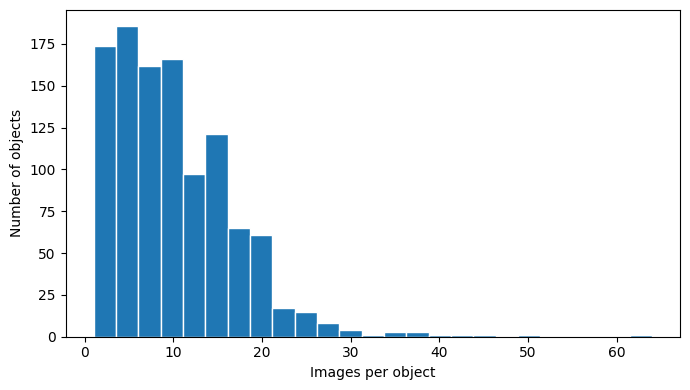

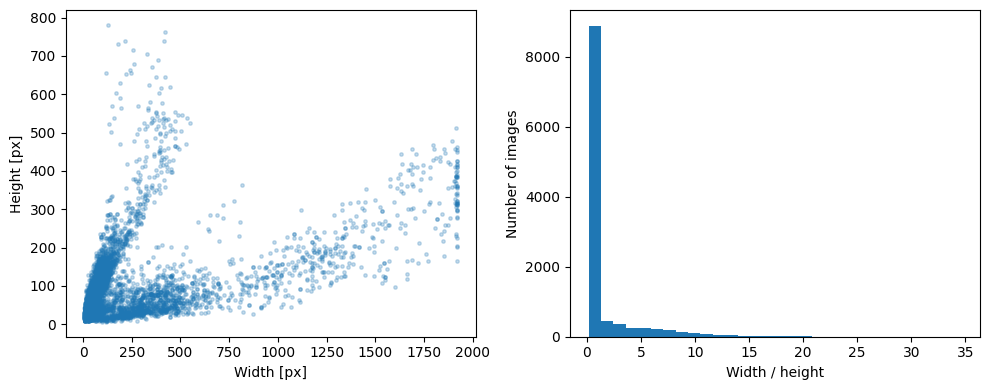

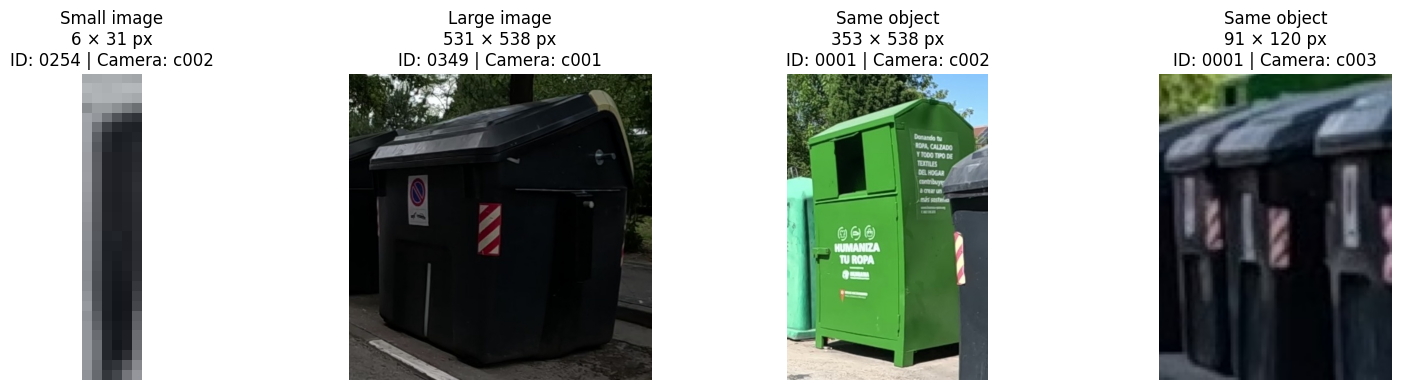

In [7]:
# Compare the number of images and objects in each category.
category_stats = labeled.groupby("category").agg(
    images=("image_name", "size"),
    objects=("object_id", "nunique"),
)
display(category_stats)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
category_stats["images"].plot.bar(ax=axes[0], title="Images per category")
category_stats["objects"].plot.bar(ax=axes[1], title="Objects per category")
fig.tight_layout()
fig.savefig(OUT / "categories.png", dpi=150)
plt.show()

# Count the available views of each object.
image_counts = labeled.groupby("object_id").size()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(image_counts, bins=25, edgecolor="white")
ax.set(xlabel="Images per object", ylabel="Number of objects")
fig.tight_layout()
fig.savefig(OUT / "images_per_object.png", dpi=150)
plt.show()

# Inspect image dimensions before choosing a model input size.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(labeled["width"], labeled["height"], s=6, alpha=0.25)
axes[0].set(xlabel="Width [px]", ylabel="Height [px]")
axes[1].hist(labeled["width"] / labeled["height"], bins=30)
axes[1].set(xlabel="Width / height", ylabel="Number of images")
fig.tight_layout()
fig.savefig(OUT / "image_sizes.png", dpi=150)
plt.show()

# Show small and large images, plus two views of the same object.
short_side = labeled[["width", "height"]].min(axis=1)
examples = [
    ("Small image", labeled.loc[short_side.idxmin()]),
    ("Large image", labeled.loc[short_side.idxmax()]),
]

camera_counts = labeled.groupby("object_id")["camera"].nunique()
if camera_counts.max() >= 2:
    object_id = camera_counts.idxmax()
    views = labeled.loc[labeled["object_id"].eq(object_id)]
    views = views.drop_duplicates("camera").head(2)
    examples.extend(("Same object", row) for _, row in views.iterrows())

fig, axes = plt.subplots(1, len(examples), figsize=(4 * len(examples), 4))
for ax, (title, row) in zip(axes, examples):
    with Image.open(ROOT / row["image_path"]) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(
        f"{title}\n{int(row['width'])} × {int(row['height'])} px\n"
        f"ID: {row['object_id']} | Camera: {row['camera']}"
    )
    ax.axis("off")

fig.tight_layout()
fig.savefig(OUT / "example_images.png", dpi=150)
plt.show()

In [18]:
SEED = 2026
TEST_FRACTION = 0.15
N_QUERY_IMAGES = 100

rng = np.random.default_rng(SEED)

# Split by object ID so all images of an object stay together.
object_ids = sorted(labeled["object_id"].unique())
n_test = round(TEST_FRACTION * len(object_ids))
test_ids = set(rng.permutation(object_ids)[:n_test])

is_test = labeled["object_id"].isin(test_ids)
train = labeled.loc[~is_test].copy()
local_test = labeled.loc[is_test].sort_values("image_path").copy()

# Assign integer labels to the training objects.
train_ids = sorted(train["object_id"].unique())
label_by_id = {object_id: i for i, object_id in enumerate(train_ids)}
train["train_label"] = train["object_id"].map(label_by_id)

# Reserve one gallery image for each test object.
reserved_indices = []
for _, group in local_test.groupby("object_id"):
    reserved_indices.append(rng.choice(group.index.to_numpy()))

# Any image that was not reserved can be picked as a query.
query_candidates = local_test.drop(index=reserved_indices)

if not 1 <= N_QUERY_IMAGES <= len(query_candidates):
    raise ValueError(
        f"N_QUERY_IMAGES must be between 1 and {len(query_candidates)} "
        "to leave at least one gallery image per test object."
    )

# Sample images without replacement. An object can have several queries.
query_indices = rng.choice(
    query_candidates.index.to_numpy(),
    size=N_QUERY_IMAGES,
    replace=False,
)

query = local_test.loc[query_indices].copy()
gallery = local_test.drop(index=query_indices).copy()

# Record every correct gallery match for each query image.
matches = query[["object_id", "image_path"]].merge(
    gallery[["object_id", "image_path"]],
    on="object_id",
    suffixes=("_query", "_gallery"),
)

# Check the splits and make sure every query has a gallery match.
assert set(train["object_id"]).isdisjoint(local_test["object_id"])
assert set(query["image_path"]).isdisjoint(gallery["image_path"])
assert set(gallery["object_id"]) == set(local_test["object_id"])
assert set(matches["image_path_query"]) == set(query["image_path"])

train.to_csv(OUT / "local_train.csv", index=False)
query.to_csv(OUT / "local_test_query.csv", index=False)
gallery.to_csv(OUT / "local_test_gallery.csv", index=False)
matches.to_csv(OUT / "local_test_matches.csv", index=False)

# Keep the official competition lists separate.
official["query"].to_csv(OUT / "kaggle_query.csv", index=False)
official["test"].to_csv(OUT / "kaggle_gallery.csv", index=False)

print(f"Local train: {len(train_ids)} objects, {len(train)} images")
print(f"Local test total: {len(test_ids)} objects, {len(local_test)} images")
print(f"Local test query: {query['object_id'].nunique()} objects, {len(query)} images")
print(f"Local test gallery: {gallery['object_id'].nunique()} objects, {len(gallery)} images")

Local train: 925 objects, 9612 images
Local test total: 163 objects, 1563 images
Local test query: 71 objects, 100 images
Local test gallery: 163 objects, 1463 images
